In [628]:
import pandas as pd
df=pd.read_csv("../data/Telco Customer Churn.csv")

In [629]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [630]:
df.shape

(7043, 21)

In [631]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [632]:
df_columns=df.columns.tolist()
for column in df_columns:
    print(f"{column} unique values:{df[column].unique()}")

customerID unique values:<ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
gender unique values:<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen unique values:[0 1]
Partner unique values:<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents unique values:<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
tenure unique values:[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService unique values:<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines unique values:<ArrowStringArr

In [633]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [634]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [635]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [636]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [637]:
df[['TotalCharges']].info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TotalCharges  7032 non-null   float64
dtypes: float64(1)
memory usage: 55.2 KB


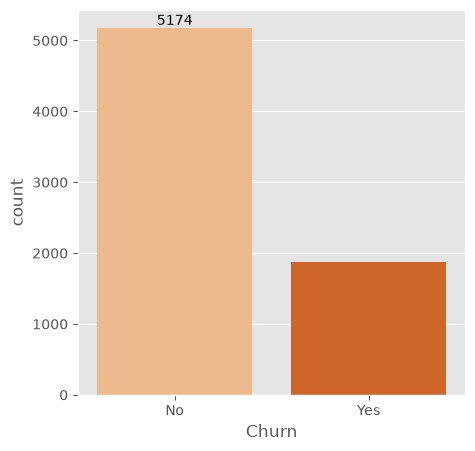

In [638]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")
plt.figure(figsize=(5,5))
axis=sns.countplot(x=df["Churn"],palette="Oranges", legend=False,hue=df["Churn"])
axis.bar_label(axis.containers[0])
plt.savefig("../visuals/target_analysis.png",dpi=300)
plt.show()

In [639]:
print(df['PaymentMethod'].unique())

<ArrowStringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


In [640]:
print(df['PhoneService'].unique())
print(df['MultipleLines'].unique())
print(df['InternetService'].unique())
print(df['OnlineSecurity'].unique())
print(df['OnlineBackup'].unique())
print(df['DeviceProtection'].unique())
print(df['TechSupport'].unique())
print(df['StreamingTV'].unique())
print(df['StreamingMovies'].unique())

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str


In [641]:
import math
def plot_categorical_to_target(df,catergorical_values,target):
    number_of_columns=2
    number_of_rows=math.ceil(len(catergorical_values)/2)

    fig=plt.figure(figsize=(12,5*number_of_rows))

    for index, column in enumerate(catergorical_values,1):
        ax=fig.add_subplot(number_of_rows,number_of_columns,index)
        ax=sns.countplot(x=column,data=df,hue=target,palette="Reds")
        plt.savefig("../visuals/categorical_data_analysis.png",dpi=300)
    return plt.show()

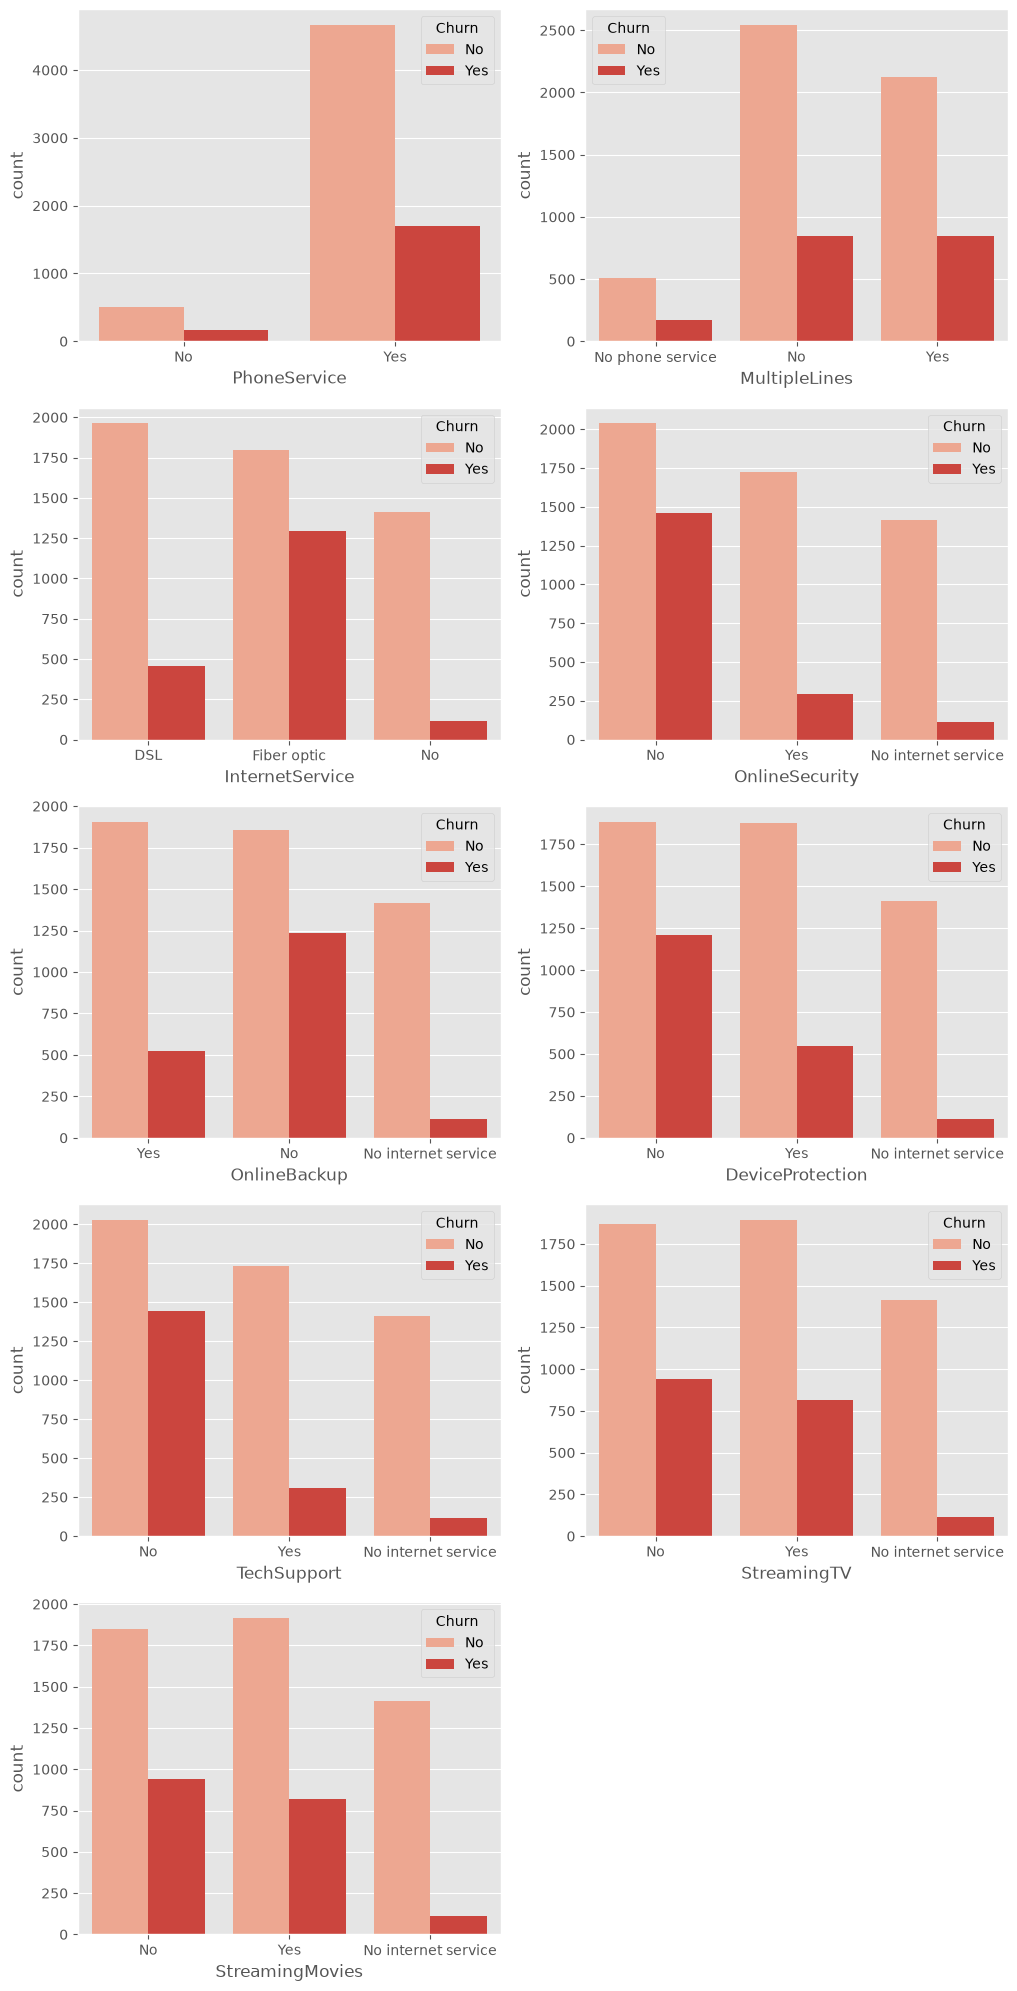

In [642]:
categories_data=["PhoneService","MultipleLines","InternetService","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
plot_categorical_to_target(df,categories_data,"Churn")

In [643]:
def numerical_data(df,numerical_values,target):
    number_of_columns=2
    number_of_rows=math.ceil(len(numerical_values)/2)

    fig=plt.figure(figsize=(12,5*number_of_rows))

    for index, column in enumerate(numerical_values,1):
        ax=fig.add_subplot(number_of_rows,number_of_columns,index)
        ax=sns.kdeplot(df[column][df[target]=="Yes"],fill=True)
        ax=sns.kdeplot(df[column][df[target]=="No"],fill=True)
        ax.legend(["Churn","No Churn"],loc='upper right')
    plt.savefig("../visuals/numerical_variables.png",dpi=300)
    return plt.show()


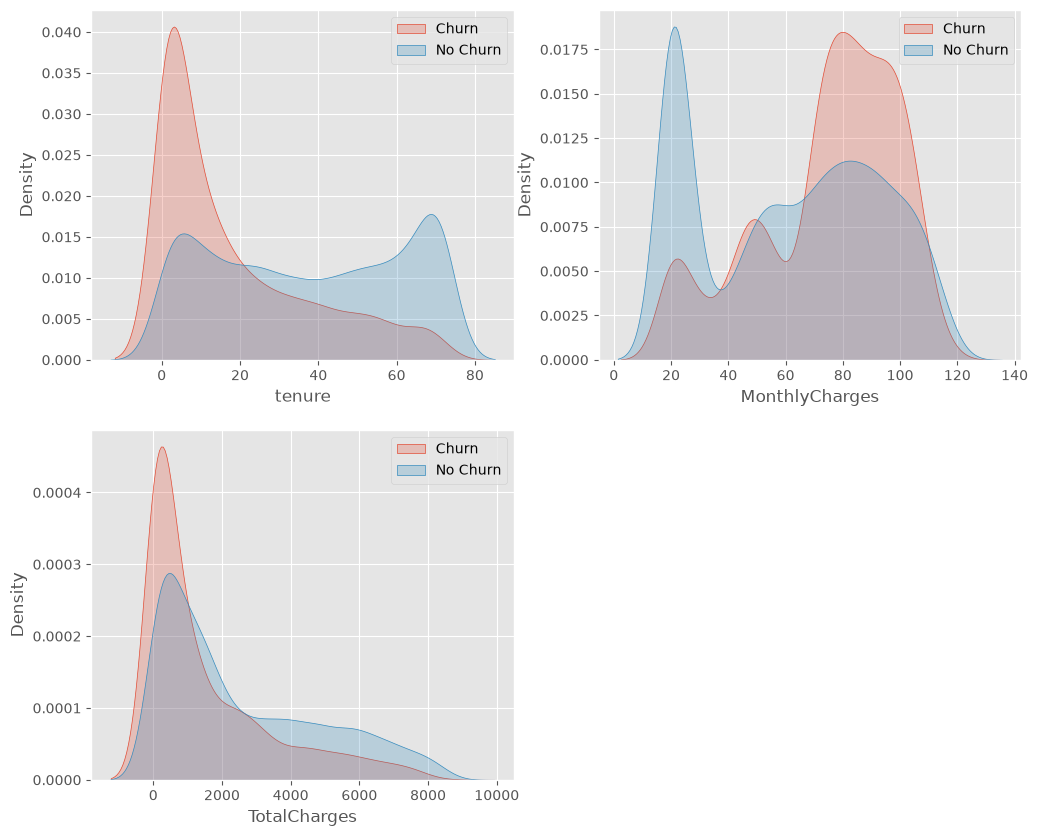

In [644]:
numerics=["tenure","MonthlyCharges","TotalCharges"]
numerical_data(df,numerics,"Churn")

In [645]:
def outlier_check(df,numerical_values):
    number_of_columns=2
    number_of_rows=math.ceil(len(numerical_values)/2)

    fig=plt.figure(figsize=(12,5*number_of_rows))
    for index, column in enumerate(numerical_values,1):
        ax=fig.add_subplot(number_of_rows,number_of_columns,index)
        ax=sns.boxplot(x=column,data=df,palette="Reds")
    plt.savefig("../visuals/outliers.png",dpi=300)
    return plt.show()

C:\Users\Rajesh.Sudam\AppData\Local\Temp\ipykernel_28060\194446556.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.boxplot(x=column,data=df,palette="Reds")
C:\Users\Rajesh.Sudam\AppData\Local\Temp\ipykernel_28060\194446556.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.boxplot(x=column,data=df,palette="Reds")
C:\Users\Rajesh.Sudam\AppData\Local\Temp\ipykernel_28060\194446556.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.boxplot(x=column,data=df,palette="Reds")


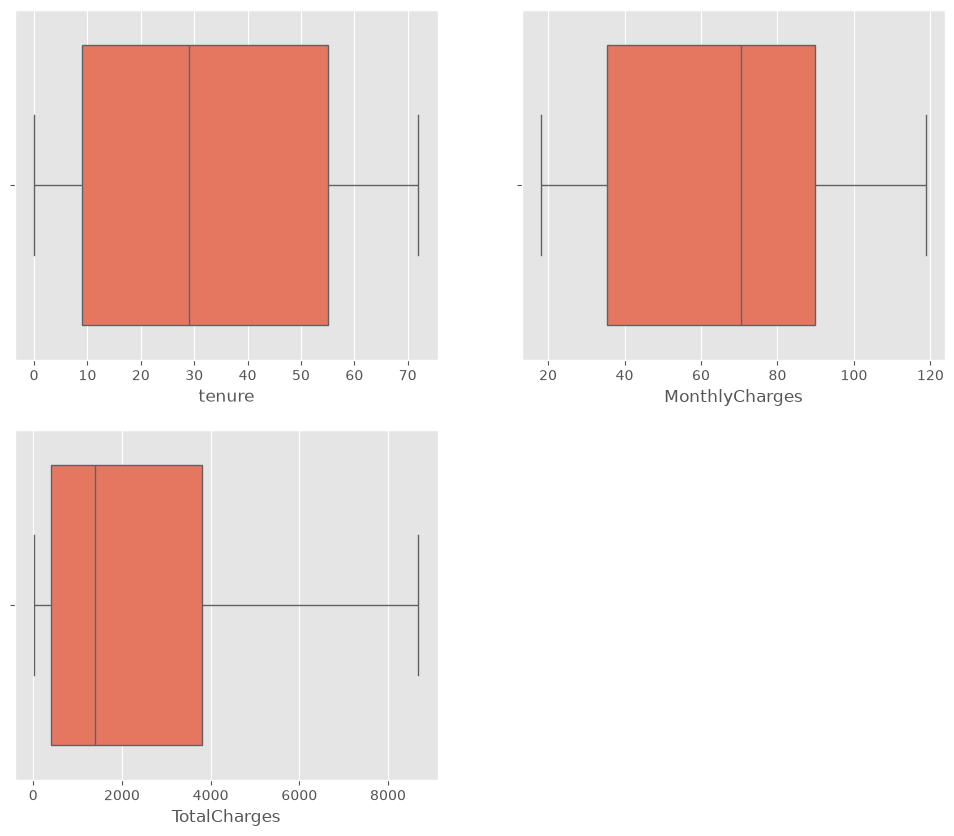

In [646]:
numerical_values=["tenure","MonthlyCharges","TotalCharges"]
outlier_check(df,numerical_values)

In [647]:

def label_encoding(df,features):
    for i in features:
        df[i]=df[i].map({"Yes":1,"No":0})
    return df

In [648]:
feature_le=["Partner","Dependents","PhoneService","Churn"]
df=label_encoding(df,feature_le)
df["gender"]=df["gender"].map({"Female":1,"Male":0})

In [649]:
print(df["gender"].unique())
print(df["PhoneService"].unique())
print(df["Dependents"].unique())
print(df["Churn"].unique())

[1 0]
[0 1]
[0 1]
[0 1]


In [650]:
df[["gender","Partner","Dependents","PhoneService","Churn"]].dtypes

gender          int64
Partner         int64
Dependents      int64
PhoneService    int64
Churn           int64
dtype: object

In [651]:
df[["gender","Partner","Dependents","PhoneService","Churn"]].head()

,gender,Partner,Dependents,PhoneService,Churn
0,1,1,0,0,0
1,0,0,0,1,0
2,0,0,0,1,1
3,0,0,0,0,0
4,1,0,0,1,1


In [652]:
features_ohe=["MultipleLines","InternetService","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract","PaperlessBilling","PaymentMethod"]
df_ohe=pd.get_dummies(df, columns=features_ohe)

In [653]:
# Feature Scaling
from sklearn.preprocessing import MinMaxScaler


features_scaling=["tenure","MonthlyCharges","TotalCharges"]
df_scaling=pd.DataFrame(df_ohe, columns=features_scaling)
df_remaining=df_ohe.drop(columns=features_scaling)

scaling=MinMaxScaler(feature_range=(0,1))
rescaled_feature=scaling.fit_transform(df_scaling)

rescaled_feature_df=pd.DataFrame(rescaled_feature, columns=features_scaling,index=df_scaling.index)
df=pd.concat([rescaled_feature_df,df_remaining],axis=1)

In [654]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 43 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   tenure                                   7043 non-null   float64
 1   MonthlyCharges                           7043 non-null   float64
 2   TotalCharges                             7032 non-null   float64
 3   customerID                               7043 non-null   str    
 4   gender                                   7043 non-null   int64  
 5   SeniorCitizen                            7043 non-null   int64  
 6   Partner                                  7043 non-null   int64  
 7   Dependents                               7043 non-null   int64  
 8   PhoneService                             7043 non-null   int64  
 9   Churn                                    7043 non-null   int64  
 10  MultipleLines_No                         7043 non-null   bo

In [655]:
df.select_dtypes(include=["object","string"]) 

,customerID
0,7590-VHVEG
1,5575-GNVDE
2,3668-QPYBK
3,7795-CFOCW
4,9237-HQITU
...,...
7038,6840-RESVB
7039,2234-XADUH
7040,4801-JZAZL
7041,8361-LTMKD


In [656]:
df["TotalCharges"].isna().sum()

np.int64(11)

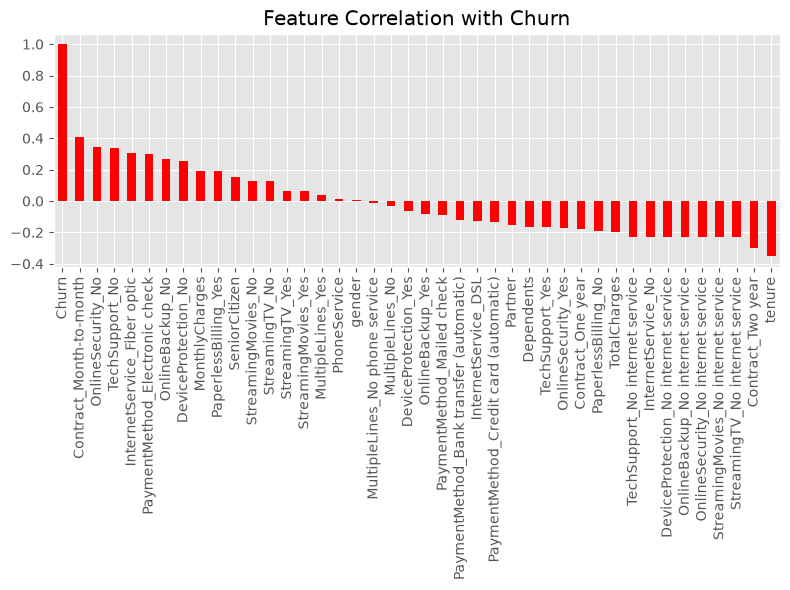

In [657]:
plt.figure(figsize=(8,6))

numerical_df=df.select_dtypes(include=["number","bool"])
numerical_df.corr()["Churn"]\
    .sort_values(ascending=False)\
    .plot(kind="bar",color="Red")
plt.title("Feature Correlation with Churn")
plt.tight_layout()
plt.savefig("../visuals/correlation_analysis.png", dpi=300)
plt.show()

In [658]:
from sklearn.model_selection import train_test_split

X=df.drop(columns="Churn")
y=df["Churn"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5634, 42), (1409, 42), (5634,), (1409,))

In [ ]:
import sqlite3

csv_path='../data/Telco Customer Churn.csv'
db_path='../data/database.csv'

df=pd.read_csv(csv_path)

conn=sqlite3.connect(db_path)

df.to_sql('customers', conn, if_exists='replace', index=False)

conn.close()
print("Connected to SQL")


Connected to SQL


In [ ]:
import sqlite3

# Connects to database.db (creates it if it doesn't exist)
conn = sqlite3.connect("telco.db")
cursor = conn.cursor()

# Create a sample table
cursor.execute("""
    CREATE TABLE IF NOT EXISTS users (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        name TEXT NOT NULL
    )
""")

# Commit changes and close the connection
conn.commit()
conn.close()
print("Database connected and table created successfully!")

Database connected and table created successfully!
